# From sunlight measurements to cloud fluctuations

Solar irradiance follows a predictable daily and seasonal pattern determined largely by the Sun's position. Actual measurements, however, can fluctuate sharply as clouds move across the sky. SkyFlux investigates whether simple statistical models can reproduce these fluctuations once the predictable solar variation is separated out.

We use ten-minute global horizontal irradiance (GHI) observations from the German Weather Service (DWD), recorded at Belm, Germany, during 2020–2025. The years 2020–2023 form the training period, 2024 is used for validation, and 2025 is reserved for the final evaluation.

## Separating solar geometry from cloud variability

We express measured irradiance as

$$
G(t) = G_{\mathrm{clear,cal}}(t)\,k(t),
$$

where

- $G(t)$ is the measured GHI at time $t$,
- $G_{\mathrm{clear,cal}}(t)$ is a calibrated clear-sky reference computed with the *Ineichen model*, and
- $k(t)$ is the dimensionless cloud factor that remains once the solar geometry is divided out — the quantity usually called the *clear-sky index* in the solar-energy literature.

The clear-sky reference is a model, not a measurement of what the irradiance would have been without clouds. Its multiplicative calibration factor (1.0732) was estimated from clear periods in the 2020–2023 training years so that $k \approx 1$ under clear skies. Because the reference remains a model, $k$ can exceed one.

The cloud factor is defined only on valid daylight measurements, where daylight is defined by the original uncalibrated reference being at least 25 W/m². Missing observations are kept separately — as a validity mask — rather than treated as zero irradiance, so a gap is never read as darkness or heavy attenuation.

All figures below are rendered from pre-exported assets built by `scripts/export_notebook_assets.py`, so the notebook runs without access to the raw DWD record.


In [1]:
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt

asset_path = Path("assets/representative_days.npz")
if not asset_path.exists():
    asset_path = Path("notebooks/assets/representative_days.npz")

with np.load(asset_path, allow_pickle=False) as archive:
    days = {name: archive[name] for name in archive.files}

metadata = json.loads(days["meta_json"].item())
labels = days["labels"].tolist()

print("Station:", metadata["station"]["station_name"])
for entry in metadata["selection"]["criteria"]:
    print(f"{entry['label']:20s} {entry['date']}")

Station: Belm
clearest             2021-02-13
most_overcast        2023-02-17
most_intermittent    2020-07-12
cloud_enhancement    2020-09-18
shortest_day         2020-12-13
longest_day          2020-06-08
partial_data         2020-06-24


Seven selected example days are available, spanning a range of conditions: clearest, most overcast, most intermittent, cloud enhancement, shortest and longest day, and a day with partial data. This notebook examines the three that best motivate the decomposition — the most intermittent day and the two cloud-factor extremes.


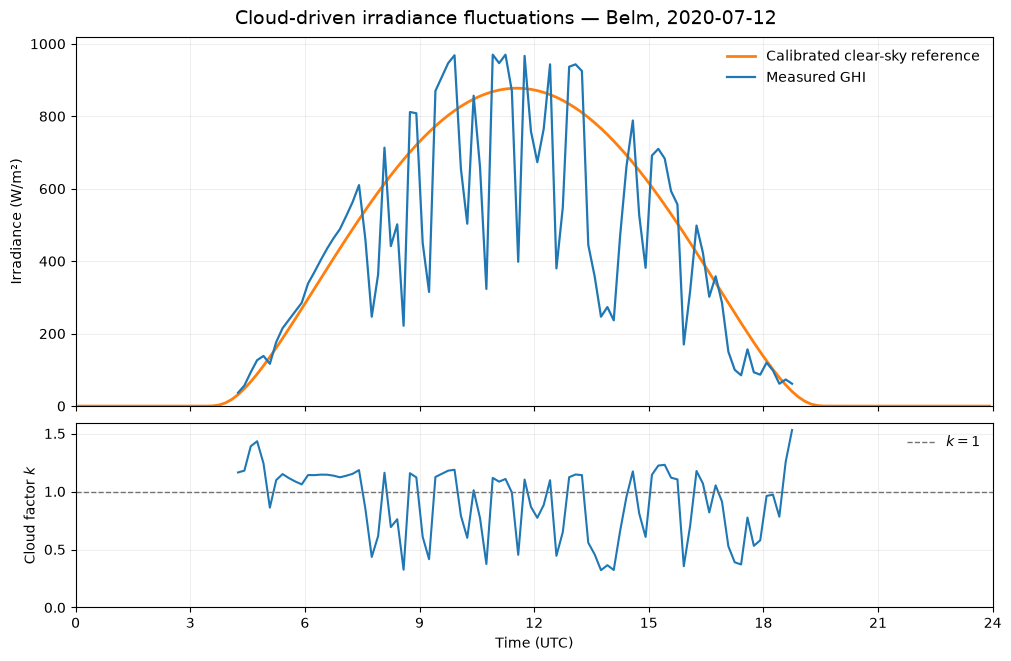

In [2]:
idx = labels.index("most_intermittent")

t = days["slot_hours_utc"]
date = str(days["dates"][idx])
valid = days["status"][idx] == 1  # Valid daylight measurement

ghi = np.where(valid, days["ghi"][idx], np.nan)
g_clear = days["g_clear_calibrated"][idx]
k = np.where(valid, days["k_calibrated"][idx], np.nan)

fig, (ax_g, ax_k) = plt.subplots(
    2, 1,
    figsize=(10, 6.5),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
    layout="constrained",
)

ax_g.plot(
    t, g_clear,
    color="tab:orange", linewidth=2,
    label="Calibrated clear-sky reference",
)
ax_g.plot(
    t, ghi,
    color="tab:blue", linewidth=1.6,
    label="Measured GHI",
)
ax_g.set_ylabel("Irradiance (W/m²)")
ax_g.set_ylim(bottom=0)
ax_g.legend(frameon=False)
ax_g.grid(alpha=0.2)

ax_k.plot(t, k, color="tab:blue", linewidth=1.5)
ax_k.axhline(
    1, color="0.45", linestyle="--",
    linewidth=1, label="$k = 1$",
)
ax_k.set_ylabel("Cloud factor $k$")
ax_k.set_xlabel("Time (UTC)")
ax_k.set_ylim(bottom=0)
ax_k.set_xlim(0, 24)
ax_k.set_xticks(np.arange(0, 25, 3))
ax_k.legend(frameon=False)
ax_k.grid(alpha=0.2)

fig.suptitle(
    f"Cloud-driven irradiance fluctuations — Belm, {date}",
    fontsize=14,
)

plt.show()

The figure above shows the most intermittent day in the training period, 12 July 2020, selected for its large ten-minute irradiance fluctuations. The upper panel compares the measured GHI (blue) with the calibrated clear-sky reference (orange). The reference follows the smooth daily course of the Sun, while measured irradiance fluctuates sharply as cloud conditions change.

The lower panel shows the cloud factor $k(t)$, obtained by dividing the measured irradiance by the clear-sky reference. The rapid fluctuations remain visible, but are now expressed on a dimensionless scale that makes morning and afternoon measurements easier to compare. The dashed line marks $k=1$, where measured irradiance equals the reference.

Values above one are possible and can be genuine cloud enhancement. They should not, however, be read as confirmation of it: near the edges of the daylight window the Sun is low and the reference is least reliable, so model error alone can push $k$ above one.


## Contrasting cloud conditions

The July day above shows how quickly irradiance can fluctuate within a single day. Cloud conditions also affect the overall level of irradiance relative to the clear-sky reference. To illustrate this second aspect, we compare two further days from the 2020–2023 training period, selected by their median calibrated $k$ over valid daylight measurements:

- **Clearest day:** 13 February 2021, the day with the highest median $k$.
- **Most overcast day:** 17 February 2023, the day with the lowest median $k$.

Both dates fall in February, so their daylight windows and modelled clear-sky irradiance are broadly comparable. Normalization reduces the influence of solar geometry, making the substantial difference in cloud-factor levels easier to interpret.

These are deliberately selected extremes, not typical days. And because $k$ is defined relative to a modelled reference, a high or low value is consistent with clear or overcast conditions but does not by itself establish them.


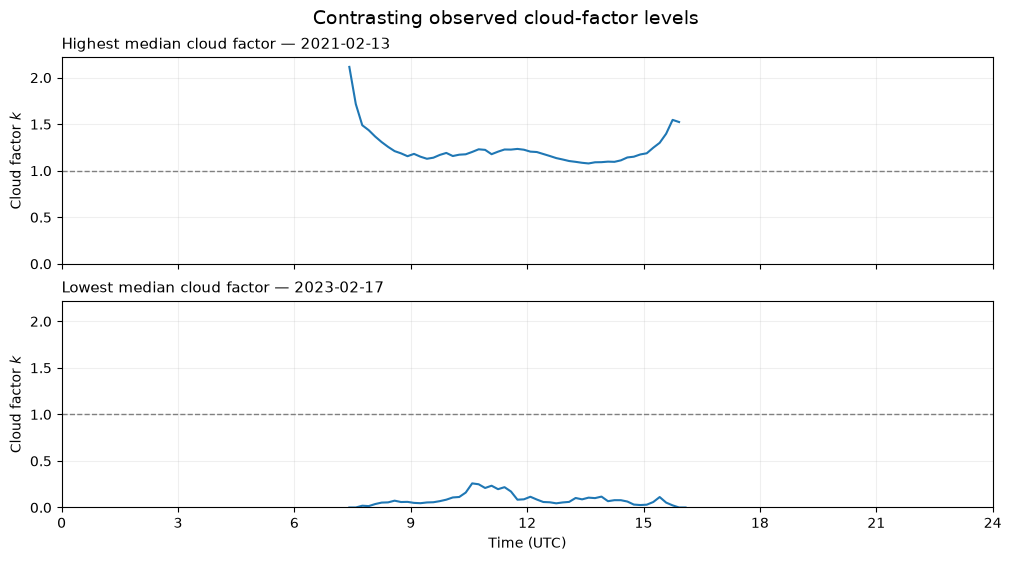

In [3]:
examples = [
    ("clearest", "Highest median cloud factor"),
    ("most_overcast", "Lowest median cloud factor"),
]

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 5.5),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for ax, (key, description) in zip(axes, examples):
    i = labels.index(key)
    valid = days["status"][i] == 1
    profile = np.where(
        valid, days["k_calibrated"][i], np.nan
    )

    ax.plot(t, profile, color="tab:blue", linewidth=1.5)
    ax.axhline(
        1, color="0.5", linestyle="--", linewidth=1
    )
    ax.set_title(
        f"{description} — {days['dates'][i]}",
        loc="left", fontsize=11,
    )
    ax.set_ylabel("Cloud factor $k$")
    ax.grid(alpha=0.2)

axes[0].set_ylim(bottom=0)
axes[-1].set_xlim(0, 24)
axes[-1].set_xticks(np.arange(0, 25, 3))
axes[-1].set_xlabel("Time (UTC)")

fig.suptitle(
    "Contrasting observed cloud-factor levels",
    fontsize=14,
)

plt.show()

Taken together, the three profiles show why a single summary statistic cannot characterize cloud variability. The two February days differ mainly in the typical level of the cloud factor; the July day differs in how rapidly it changes. A day's typical level and its short-term dynamics are distinct properties, and a useful generative model should capture both.

Our generative models are therefore judged on more than the distribution of instantaneous values. Generated profiles are compared with observations from a held-out year along complementary axes: daily irradiation (the total energy received), ten-minute changes (the short-term dynamics) and temporal autocorrelation (the persistence of conditions within a day).
